# Sustainable Supply Chains and Green Energy Optimization

## Dataset: Green Supply Chain Dataset
https://www.kaggle.com/datasets/ziya07/green-supply-chain-dataset

### Data Import

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import ExtraTreesRegressor
import xgboost as xgb
import matplotlib.pyplot as plt
import seaborn as sns

### Display dataset for visibility
### Key Features:
#### Product Type: Categorized into Electronics, Apparel, Automotive, Pharmaceutical, and Food.
#### Resource Usage: Raw material consumption, energy consumption, and waste generation.
#### Environmental Impact: CO₂ emissions, renewable energy usage, and sustainability score.
#### Operational Metrics: Transportation distance, manufacturing energy, cost, and delivery time.
#### Target Variable: Sustainability Score, calculated based on emissions, waste, renewable energy, and cost.

In [2]:
df = pd.read_csv('green_supply_chain_dataset_1000.csv')
print(df.head()) 

   ID    Product_Type  Raw_Material_Usage_kg  Energy_Consumption_kWh  \
0   1  Pharmaceutical             187.102474              372.345525   
1   2            Food             117.375305               82.437951   
2   3      Automotive             142.363657               82.065527   
3   4            Food             185.274882               55.448814   
4   5            Food             144.375341              480.425629   

   Waste_Generated_kg  Transport_Distance_km  CO2_Emissions_kg  \
0            4.580997            2708.230192        206.072501   
1           31.494820             605.998543        794.003359   
2           49.077714             945.366997        166.372969   
3           10.315275            2883.074057        653.161326   
4           39.837161            1552.152306        167.653725   

   Manufacturing_Energy_kWh  Renewable_Energy_%       Cost_$  \
0                195.022097           77.312801  4696.896464   
1                784.206729           31.8

### Preprocessing

In [3]:
X = df.drop(columns=["Sustainability_Score"])
y = df["Sustainability_Score"]

categorical_cols = ["Product_Type"]
numeric_cols = [col for col in X.columns if col not in categorical_cols]
preprocess = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
        ("num", "passthrough", numeric_cols),
    ]
)

#### splitting the data into Test, Train, and validation sets

In [4]:
# 70% train, 30% temp
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42
)

# Split temp into 50/50 → 15% validation, 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42
)

### Setting a baseline model with Random forest 

In [5]:
rf_model = Pipeline(steps=[
    ("preprocess", preprocess),
    ("model", RandomForestRegressor(n_estimators=300, random_state=42))
])
rf_model.fit(X_train, y_train)

,steps,"[('preprocess', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('cat', ...), ('num', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [6]:
y_pred_val_rf = rf_model.predict(X_val)
y_pred_test_rf = rf_model.predict(X_test)

rf_r2sc = r2_score(y_val, y_pred_val_rf)
rf_val_RSME = np.sqrt(mean_squared_error(y_val, y_pred_val_rf))
rf_test_r2sc = r2_score(y_test, y_pred_test_rf)
rf_test_RSME = np.sqrt(mean_squared_error(y_test, y_pred_test_rf))

print("\nRandom Forest Performance:")
print("Validation R²:", r2_score(y_val, y_pred_val_rf))
print("Validation RMSE:", np.sqrt(mean_squared_error(y_val, y_pred_val_rf)))
print("Test R²:", r2_score(y_test, y_pred_test_rf))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_test_rf)))


Random Forest Performance:
Validation R²: 0.9539543948422848
Validation RMSE: 3.266307050234995
Test R²: 0.9558281714234539
Test RMSE: 3.1465663509586332


### Testing with Extra Tree Regressor

In [7]:
et_model = Pipeline(steps=[
    ("preprocess", preprocess),
    ("model", ExtraTreesRegressor(n_estimators=300, random_state=42))
])
et_model.fit(X_train, y_train)

,steps,"[('preprocess', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('cat', ...), ('num', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [8]:
y_pred_val_rf = et_model.predict(X_val)
y_pred_test_rf = et_model.predict(X_test)
print("\nRandom Forest Performance:")
print("Validation R²:", r2_score(y_val, y_pred_val_rf))
print("Validation RMSE:", np.sqrt(mean_squared_error(y_val, y_pred_val_rf)))
print("Test R²:", r2_score(y_test, y_pred_test_rf))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_test_rf)))


Random Forest Performance:
Validation R²: 0.9703014201169744
Validation RMSE: 2.623196095266665
Test R²: 0.9766560966380271
Test RMSE: 2.287446489501628


### Testing with XGB model for

In [9]:
xgb_model = Pipeline(steps=[
    ("preprocess", preprocess),
    ("model", xgb.XGBRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.7,
        colsample_bytree=0.8,
        random_state=42,
        objective="reg:squarederror"
    ))
])

In [10]:
xgb_model.fit(X_train, y_train)

y_pred_val_xgb = xgb_model.predict(X_val)
y_pred_test_xgb = xgb_model.predict(X_test)

print("\n⚡ XGBoost Performance:")
print("Validation R²:", r2_score(y_val, y_pred_val_xgb))
print("Validation RMSE:", np.sqrt(mean_squared_error(y_val, y_pred_val_xgb)))
print("Test R²:", r2_score(y_test, y_pred_test_xgb))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_test_xgb)))


⚡ XGBoost Performance:
Validation R²: 0.975925597108425
Validation RMSE: 2.361786728768999
Test R²: 0.9792436381769353
Test RMSE: 2.156948725886314


### Checking which features are contributing the most.


Top Feature Drivers of Sustainability Score:


,feature,importance
12,Renewable_Energy_%,0.415252
10,CO2_Emissions_kg,0.289316
8,Waste_Generated_kg,0.133237
13,Cost_$,0.045108
11,Manufacturing_Energy_kWh,0.022813
14,Delivery_Time_days,0.016093
6,Raw_Material_Usage_kg,0.014808
9,Transport_Distance_km,0.012761
5,ID,0.011612
3,Product_Type_Food,0.008703


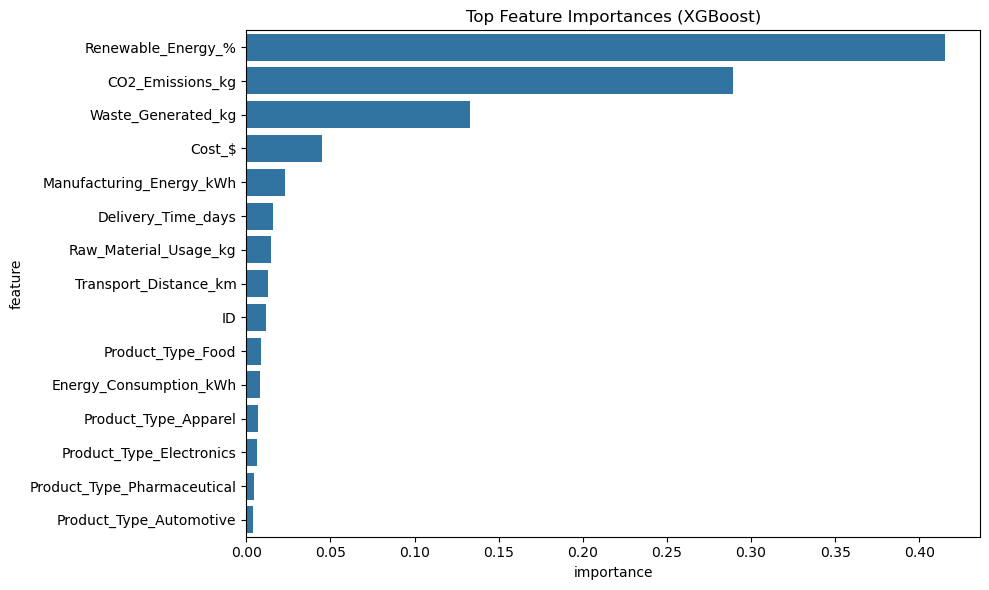

In [11]:
ohe = xgb_model.named_steps["preprocess"].named_transformers_["cat"]
cat_features = list(ohe.get_feature_names_out(categorical_cols))
feature_names = cat_features + numeric_cols

importances = xgb_model.named_steps["model"].feature_importances_

fi_df = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
}).sort_values("importance", ascending=False)

print("\nTop Feature Drivers of Sustainability Score:")
display(fi_df.head(15))

plt.figure(figsize=(10,6))
sns.barplot(data=fi_df.head(15), x="importance", y="feature")
plt.title("Top Feature Importances (XGBoost)")
plt.tight_layout()
plt.show()

# The most important features are as expected since the Sustainability score was based on cost, waste, and CO2

In [12]:
import numpy as np

# Define bins from training data
bins = [
    -np.inf,
    y_train.quantile(0.33),
    y_train.quantile(0.66),
    np.inf
]

labels = [0, 1, 2]  # Low, Medium, High


In [13]:
y_test_cls = np.digitize(y_test, bins) - 1
y_pred_cls = np.digitize(y_pred_test_xgb, bins) - 1


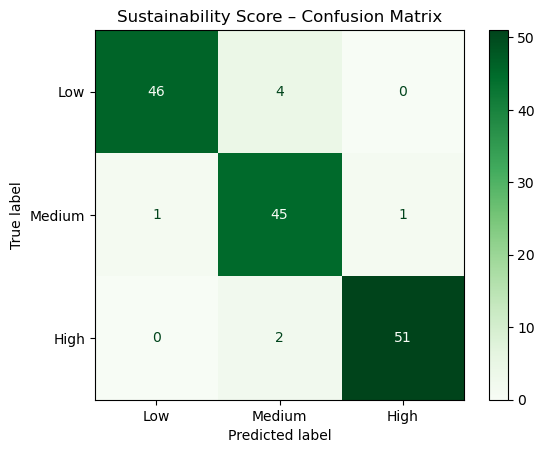

In [14]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test_cls, y_pred_cls, labels=labels)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Low", "Medium", "High"]
)

disp.plot(cmap="Greens")
plt.title("Sustainability Score – Confusion Matrix")
plt.show()


In [15]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test_cls,
    y_pred_cls,
    target_names=["Low", "Medium", "High"]
))


              precision    recall  f1-score   support

         Low       0.98      0.92      0.95        50
      Medium       0.88      0.96      0.92        47
        High       0.98      0.96      0.97        53

    accuracy                           0.95       150
   macro avg       0.95      0.95      0.95       150
weighted avg       0.95      0.95      0.95       150



In [16]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_squared_error

models = ["XGBoost", "Extra Tree Forest", "Random Forest"]




val_r2 = [
    
    r2_score(y_val, y_pred_val_xgb),
    r2_score(y_val, y_pred_val_rf),
    rf_r2sc
]

test_r2 = [
    r2_score(y_test, y_pred_test_xgb),
    r2_score(y_test, y_pred_test_rf),
    rf_test_r2sc
]

val_rmse = [
    np.sqrt(mean_squared_error(y_val, y_pred_val_xgb)),
    np.sqrt(mean_squared_error(y_val, y_pred_val_rf)),
    rf_val_RSME
]

test_rmse = [
    np.sqrt(mean_squared_error(y_test, y_pred_test_xgb)),
    np.sqrt(mean_squared_error(y_test, y_pred_test_rf)),
    rf_test_RSME
]


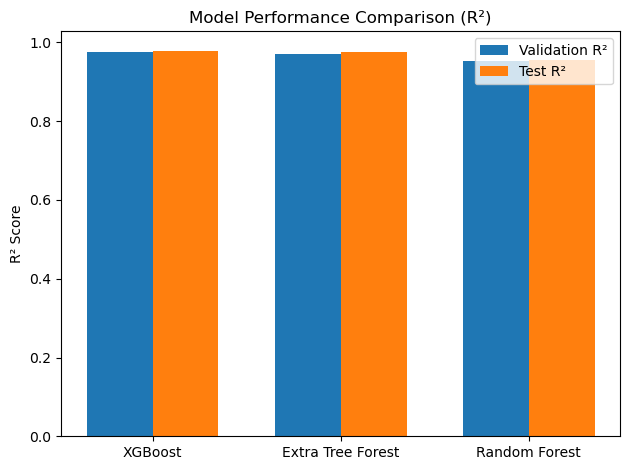

In [17]:
x = np.arange(len(models))
width = 0.35

plt.figure()
plt.bar(x - width/2, val_r2, width, label="Validation R²")
plt.bar(x + width/2, test_r2, width, label="Test R²")

plt.xticks(x, models)
plt.ylabel("R² Score")
plt.title("Model Performance Comparison (R²)")
plt.legend()
plt.tight_layout()
plt.show()


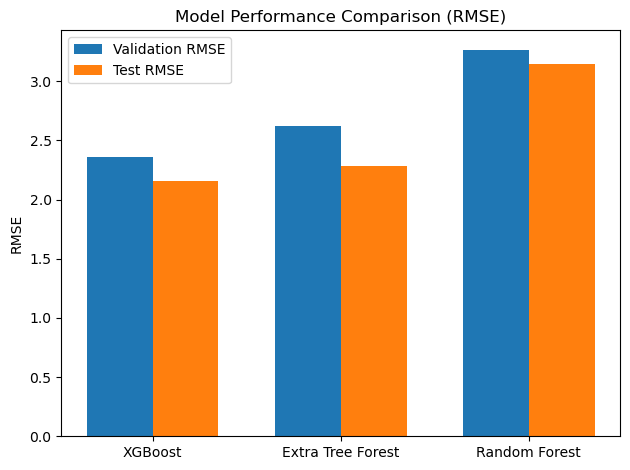

In [18]:
plt.figure()
plt.bar(x - width/2, val_rmse, width, label="Validation RMSE")
plt.bar(x + width/2, test_rmse, width, label="Test RMSE")

plt.xticks(x, models)
plt.ylabel("RMSE")
plt.title("Model Performance Comparison (RMSE)")
plt.legend()
plt.tight_layout()
plt.show()


In [19]:
print("Val std:", y_val.std())
print("Test std:", y_test.std())

Val std: 15.272685583294594
Test std: 15.02161753891566


# The standardization helps understand why the RSME is similar with TEST dataset and Validation dataset.